# DỰ BÁO ĐỘ MẶN NƯỚC BỀ MẶT BẰNG MÔ HÌNH HỌC MÁY LAI & QUÁ TRÌNH GAUSSIAN KHÔNG GIAN - THỜI GIAN
### Khắc phục triệt để Data Leakage & Tích hợp Spatio-Temporal Residual Gaussian Process
---
**Các điểm cải tiến cốt lõi so với phương pháp cũ:**
1. **Triệt tiêu Data Leakage:** Không sử dụng BMA chọn đặc trưng trên toàn bộ dataset; không chia ngẫu nhiên (Random Row Split) trên chuỗi thời gian.
2. **Phân chia dữ liệu theo Thời gian (Temporal Split):** Sử dụng dữ liệu năm 2019 đến hết tháng 02/2020 làm tập Train (~70%) và từ tháng 03/2020 đến hết tháng 06/2020 làm tập Test độc lập (~30%).
3. **Tái tạo đặc trưng thời gian chu kỳ tuần hoàn:** Giải mã 37 cột nhị phân cũ, loại bỏ 22 dòng khuyết ngày, mã hóa chu kỳ mùa vụ 365 ngày qua cặp biến `sin_doy` và `cos_doy`.
4. **Mô hình lai Không gian - Thời gian:** Dùng các mô hình Cây (Random Forest, Bagging, XGBoost, LightGBM, PSO-RF, PSO-Bagging) học quan hệ phi tuyến viễn thám, kết hợp Quá trình Gaussian (Gaussian Process) học phần sai số (residual) theo thời gian tuyệt đối và theo không gian để bù đắp sai số còn sót lại.
**Bài toán đang giải:** dự báo độ mặn **sau khi đã có ảnh vệ tinh của chính ngày đó**, cho một giai đoạn tương lai chưa từng thấy (train đến hết 2/2020, test từ 3/2020). Không dùng số đo thật của ngày đang dự báo. Hai cách chấm: **tĩnh** (chốt mô hình rồi dự báo cả giai đoạn) và **cuốn chiếu** (được dùng số đo của các cảnh ĐÃ QUA).
6. **Cờ thí nghiệm (Cell 4):** `USE_SEASONAL` (có/không dùng sin/cos_doy), `RECENCY_HALF_LIFE` (trọng số theo độ gần thời gian), `PSO_CV` (fold của PSO), `GP_TIME_LS_MAX` (cận độ dài tương quan thời gian của GP). Nên chạy cả `USE_SEASONAL=True` và `False` rồi báo cáo cả hai.
5. **Đánh giá cuốn chiếu (rolling-origin):** ngoài điểm tĩnh (chốt mô hình rồi dự báo cả tập test một lần), notebook còn chấm theo từng cảnh ảnh: mỗi cảnh test chỉ được hiệu chỉnh bằng số đo thật của các cảnh ĐÃ QUA. Mô hình nền (cây + Ridge) luôn cố định, chỉ GP được cập nhật.

In [59]:
# Cài đặt các thư viện bổ sung cần thiết: pyswarm, shap, lightgbm, xgboost
!pip install pyswarm shap lightgbm xgboost scikit-learn -q
print('Cài đặt thư viện hoàn tất.')

Cài đặt thư viện hoàn tất.


**Cell 2: Import thư viện & Định nghĩa các hàm đo lường hiệu năng chuẩn của bài báo**
- R2 (Coefficient of Determination - Hệ số xác định)
- RMSE (Root Mean Square Error - Sai số bình phương trung bình căn, đơn vị: g/l hoặc ‰)
- MAE (Mean Absolute Error - Sai số tuyệt đối trung bình, đơn vị: g/l hoặc ‰)
- Ex_VAR (Explained Variance - Phương sai giải thích, đơn vị: %)

In [60]:
import os
import re
import copy
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.base import clone
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.linear_model import Ridge
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, ConstantKernel, WhiteKernel
from pyswarm import pso
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

warnings.filterwarnings('ignore')
np.random.seed(42)

# 1. Hệ số xác định R2 (Công thức 7 bài báo)
def calc_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot) if ss_tot != 0 else 0.0

# 2. Sai số bình phương trung bình căn (RMSE - g/l) (Công thức 8 bài báo)
def calc_rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

# 3. Sai số tuyệt đối trung bình (MAE - g/l) (Công thức 9 bài báo)
def calc_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

# 4. Phương sai giải thích (Ex_VAR - %) (Công thức 10 bài báo)
def calc_explained_variance(y_true, y_pred):
    var_y = np.var(y_true)
    if var_y == 0:
        return 0.0
    return (1 - np.var(y_true - y_pred) / var_y) * 100

# 5. Độ lệch trung bình (Bias = mean(y_true - y_pred)); DƯƠNG nghĩa là mô hình đoán THẤP hơn thực tế
def calc_bias(y_true, y_pred):
    return np.mean(y_true - y_pred)

# 6. Hàm tổng hợp các chỉ số. LUÔN gọi theo thứ tự (y_true, y_pred)
def evaluate_model(y_true, y_pred):
    return {
        'RMSE (‰)': round(calc_rmse(y_true, y_pred), 3),
        'MAE (‰)': round(calc_mae(y_true, y_pred), 3),
        'R2': round(calc_r2(y_true, y_pred), 3),
        'Ex_VAR (%)': round(calc_explained_variance(y_true, y_pred), 3),
        'Bias (‰)': round(calc_bias(y_true, y_pred), 3)
    }

print('Import thư viện và định nghĩa các hàm đo lường hoàn tất.')

Import thư viện và định nghĩa các hàm đo lường hoàn tất.


**Cell 3: Đọc dữ liệu thực tế, giải mã 37 cột ngày và tạo các đặc trưng chu kỳ thời gian tuần hoàn**
- Quét và lọc 37 cột ngày nhị phân cũ (`19Th0119`, `04Th0219`...).
- Phát hiện và loại bỏ 22 dòng khuyết thông tin ngày quan trắc (toàn bộ 37 cột bằng 0).
- Giải mã tên cột ra ngày chuẩn `date`, trích xuất `doy` (Day of Year: 1 - 365), `year`, `month`.
- Tạo 2 biến tuần hoàn `sin_doy` và `cos_doy` cho mô hình cây.
- Xóa sạch 37 cột nhị phân cũ để tối ưu hóa bộ nhớ và triệt tiêu nguy cơ học vẹt.

**3.1 Chia dữ liệu theo thời gian**

In [61]:

# Danh sách các đường dẫn khả dĩ (Local, Kaggle, Colab)
DATA_PATHS = [
    'Check_BMA_Chuanhoa_LS8_20192020_159.csv',
    './Check_BMA_Chuanhoa_LS8_20192020_159.csv',
    '/kaggle/input/datasets/tienmanhh222/check-bma/Check_BMA_Chuanhoa_LS8_20192020_159.csv',
    '/kaggle/input/check-bma/Check_BMA_Chuanhoa_LS8_20192020_159.csv',
    'Check_BMA_Chuanhoa_LS8_20192020_159.csv'
]

csv_file = None
for p in DATA_PATHS:
    if os.path.exists(p):
        csv_file = p
        break

if csv_file is not None:
    print(f'-> Đang đọc dữ liệu từ: {csv_file}')
    df_raw = pd.read_csv(csv_file)
else:
    raise FileNotFoundError('Không tìm thấy file CSV Check_BMA_Chuanhoa_LS8_20192020_159.csv!')

print(f'-> Kích thước dữ liệu gốc: {df_raw.shape[0]} hàng, {df_raw.shape[1]} cột.')

# 1. Tìm tất cả các cột ngày định dạng ddThmmyy
time_cols = [col for col in df_raw.columns if re.match(r'^\d{2}Th\d{4}$', col)]
print(f'-> Tìm thấy {len(time_cols)} cột ngày nhị phân.')

# 2. Hàm giải mã tên cột (ví dụ: 19Th0119 -> datetime(2019, 1, 19))
def parse_date_column(col_name):
    day = int(col_name[0:2])
    month = int(col_name[4:6])
    year = int('20' + col_name[6:8])
    return datetime(year, month, day)

# 3. Hàm trích xuất ngày an toàn (lọc bỏ các dòng toàn số 0)
def extract_safe_date(row):
    active_cols = [col for col in time_cols if row[col] == 1]
    if len(active_cols) == 1:
        return parse_date_column(active_cols[0])
    return pd.NaT

df_clean = df_raw.copy()
df_clean['date'] = df_clean.apply(extract_safe_date, axis=1)

# 4. Loại bỏ 22 dòng khuyết ngày để dữ liệu sạch 100%
num_missing = df_clean['date'].isna().sum()
df_clean = df_clean.dropna(subset=['date']).reset_index(drop=True)
print(f'-> Đã loại bỏ {num_missing} dòng khuyết ngày. Dữ liệu sạch: {df_clean.shape[0]} mẫu.')

# 5. Tạo các biến thời gian liên tục và tuần hoàn
df_clean['doy'] = df_clean['date'].dt.dayofyear
df_clean['year'] = df_clean['date'].dt.year
df_clean['month'] = df_clean['date'].dt.month
df_clean['sin_doy'] = np.sin(2 * np.pi * df_clean['doy'] / 365.25)
df_clean['cos_doy'] = np.cos(2 * np.pi * df_clean['doy'] / 365.25)
# 6. Xóa bỏ 37 cột nhị phân cũ
df_clean = df_clean.drop(columns=time_cols)

# 7. Danh sách các đặc trưng viễn thám và địa hình đầy đủ (không lọc qua BMA)
rs_features = [
    'DEM', 'Lat', 'Long', 'EVI', 'NDBI', 'NDMI', 'NDSI', 'NDVI', 'NDWI', 'VSSI', 'SAVI',
    'COSRI', 'EVI2', 'MSI', 'ND23', 'ND47', 'SI1', 'SI2', 'SI3', 'SI4', 'SI5', 'SI6',
    'SI7', 'SI8', 'SI9', 'CA', 'B', 'G', 'R', 'NIR', 'PCA1', 'PCA2', 'PCA3', 'PCA4', 'PCA5'
]

print(f'-> Bảng dữ liệu hoàn tất chuẩn bị: {df_clean.shape[0]} hàng, {df_clean.shape[1]} cột.')
print(df_clean.columns)

-> Đang đọc dữ liệu từ: /kaggle/input/datasets/tienmanhh222/check-bma/Check_BMA_Chuanhoa_LS8_20192020_159.csv
-> Kích thước dữ liệu gốc: 532 hàng, 73 cột.
-> Tìm thấy 37 cột ngày nhị phân.
-> Đã loại bỏ 22 dòng khuyết ngày. Dữ liệu sạch: 510 mẫu.
-> Bảng dữ liệu hoàn tất chuẩn bị: 510 hàng, 42 cột.
Index(['SALINITY_OK', 'DEM', 'Lat', 'Long', 'EVI', 'NDBI', 'NDMI', 'NDSI',
       'NDVI', 'NDWI', 'VSSI', 'SAVI', 'COSRI', 'EVI2', 'MSI', 'ND23', 'ND47',
       'SI1', 'SI2', 'SI3', 'SI4', 'SI5', 'SI6', 'SI7', 'SI8', 'SI9', 'CA',
       'B', 'G', 'R', 'NIR', 'PCA1', 'PCA2', 'PCA3', 'PCA4', 'PCA5', 'date',
       'doy', 'year', 'month', 'sin_doy', 'cos_doy'],
      dtype='object')


**Cell 4: Phân chia tập dữ liệu chống rò rỉ (Temporal Data Splitting - Chuẩn 70% Train / 30% Test)**
- **Tập Huấn luyện (Train Set):** Toàn bộ năm 2019 đến hết ngày 29/02/2020 (~359 mẫu, chiếm ~70.4% dữ liệu).
- **Tập Kiểm thử (Test Set):** Từ ngày 01/03/2020 đến hết tháng 06/2020 (~151 mẫu, chiếm ~29.6% dữ liệu - giai đoạn cao điểm hạn mặn lịch sử 2020).
- **Đặc trưng mô hình Cây (`X_base` - Theo góp ý của Thầy):**
  + 35 biến viễn thám & địa hình (`rs_features`).
  + 2 biến tuần hoàn `sin_doy`, `cos_doy` để biểu diễn **tính mùa vụ**.
  + 1 biến số ngày tuyệt đối `t` để biểu diễn **thay đổi dài hạn** (long-term trend giữa các năm).
  + Tổng cộng: **38 biến đầu vào**.
- **Đặc trưng Gaussian Process:** Không gian `Lat`, `Long` (đổi sang km, chuẩn hóa theo train) và thời gian kết hợp (`t` tuyệt đối + tuần hoàn `sin_doy, cos_doy`).
- **Fold chia theo nhóm ngày (`splits`):** tạo một lần ở đây, dùng chung cho PSO, OOF, trọng số blend và phần dư của GP.
- **Nhãn mục tiêu (`y`):** Giữ nguyên nồng độ mặn thực tế `SALINITY_OK` (g/l hoặc ‰).

In [62]:
target_col = 'SALINITY_OK'

# ===== CỜ THÍ NGHIỆM =====
# Theo góp ý của Thầy: Dùng đồng thời sin-cos để biểu diễn mùa vụ và số ngày tuyệt đối để biểu diễn thay đổi dài hạn
USE_SEASONAL      = True      # True: dùng đồng thời sin_doy, cos_doy và t cho mô hình nền
RECENCY_HALF_LIFE = None        # None: không đánh trọng số | số ngày (vd 90): hàng càng gần cuối train càng nặng
PSO_CV            = 'forward'   # 'forward': fold tiến theo thời gian (khớp bài toán dự báo) | 'group': GroupKFold theo ngày
GP_TIME_LS_MAX    = 360.0    # cận trên độ dài tương quan thời gian của GP (ngày)
RUN_TAG = f"seasonal{int(USE_SEASONAL)}_hl{RECENCY_HALF_LIFE}_{PSO_CV}"   # gắn vào tên file kết quả

# 1. Phân chia theo mốc thời gian (nguyên cảnh ảnh, không cắt đôi một ngày)
train_mask = (df_clean['date'] >= '2019-01-01') & (df_clean['date'] < '2020-03-01')
test_mask  = (df_clean['date'] >= '2020-03-01')

# Sắp xếp theo ngày (ổn định) RỒI mới reset index, để mọi mảng bên dưới cùng một thứ tự
df_train = df_clean[train_mask].sort_values('date', kind='stable').reset_index(drop=True)
df_test  = df_clean[test_mask].sort_values('date', kind='stable').reset_index(drop=True)

# Thời gian tuyệt đối: số ngày kể từ cảnh đầu tiên
t_0 = df_clean['date'].min()
df_train['t'] = (df_train['date'] - t_0).dt.days
df_test['t']  = (df_test['date']  - t_0).dt.days

# 2. Ma trận đầu vào cho các Mô hình Cây (Viễn thám 35 biến + sin/cos mùa vụ + t dài hạn)
temporal_cols = ['sin_doy', 'cos_doy', 't'] if USE_SEASONAL else []
base_cols = rs_features + temporal_cols
X_train_base = df_train[base_cols].values
X_test_base  = df_test[base_cols].values

# 3. Ma trận (Lat, Long, t) – dùng cho kernel tích tùy chọn ở Cell 6.2
st_cols = ['Lat', 'Long', 't']
X_train_st = df_train[st_cols].values
X_test_st  = df_test[st_cols].values

# 4. Vector biến mục tiêu (Độ mặn thực tế)
y_train = df_train[target_col].values.astype(np.float32)
y_test  = df_test[target_col].values.astype(np.float32)

# 5. Fold chia theo NHÓM NGÀY, tạo MỘT LẦN và dùng chung cho PSO / OOF / blend / GP
groups = df_train['date'].dt.strftime('%Y%m%d').values
splits = list(GroupKFold(n_splits=5).split(X_train_base, y_train, groups))
def forward_splits(dates, n_folds=5, min_scenes=10):
    """Fold tiến theo thời gian: mỗi fold chỉ huấn luyện trên các cảnh TRƯỚC khối validation."""
    ud = np.unique(dates)
    edges = np.linspace(min_scenes, len(ud), n_folds + 1).astype(int)
    out = []
    for a, b in zip(edges[:-1], edges[1:]):
        tr = np.where(dates < ud[a])[0]
        va = np.where(np.isin(dates, ud[a:b]))[0]
        out.append((tr, va))
    return out

cv_strategy = forward_splits(df_train['date'].values) if PSO_CV == 'forward' else splits

def recency_weights(t_days, t_ref, half_life, floor=0.05):
    if half_life is None:
        return np.ones(len(t_days))
    return np.maximum(0.5 ** ((t_ref - np.asarray(t_days, float)) / half_life), floor)

def fit_weighted(model, X, y, w):
    m = clone(model)
    if isinstance(m, Pipeline):
        m.fit(X, y, **{m.steps[-1][0] + '__sample_weight': w})
    else:
        m.fit(X, y, sample_weight=w)
    return m

w_train = recency_weights(df_train['t'].values, df_train['t'].max(), RECENCY_HALF_LIFE)

# 6. In thông số kiểm tra
print('=' * 80)
print('THÔNG TIN PHÂN CHIA TẬP DỮ LIỆU HUẤN LUYỆN & KIỂM THỬ (TEMPORAL SPLIT)')
print('=' * 80)
print(f'-> Tập Train (2019 đến hết T2/2020): {X_train_base.shape[0]} mẫu, {df_train["date"].nunique()} cảnh ({X_train_base.shape[0]/df_clean.shape[0]*100:.1f}%) | Độ mặn TB: {y_train.mean():.2f} ‰')
print(f'-> Tập Test  (T3 đến T6/2020):        {X_test_base.shape[0]} mẫu, {df_test["date"].nunique()} cảnh ({X_test_base.shape[0]/df_clean.shape[0]*100:.1f}%) | Độ mặn TB: {y_test.mean():.2f} ‰')
print(f'-> Số đặc trưng đưa vào mô hình Cây:  {X_train_base.shape[1]} biến (35 viễn thám & địa hình + {len(temporal_cols)} biến thời gian: {temporal_cols})')
print(f'-> Cờ: USE_SEASONAL={USE_SEASONAL} | RECENCY_HALF_LIFE={RECENCY_HALF_LIFE} | PSO_CV={PSO_CV} | GP_TIME_LS_MAX={GP_TIME_LS_MAX}')
print(f'-> Thang đo mặn thực tế: min={y_train.min():.2f}, mean={y_train.mean():.2f}, max={y_train.max():.2f} (‰)')


THÔNG TIN PHÂN CHIA TẬP DỮ LIỆU HUẤN LUYỆN & KIỂM THỬ (TEMPORAL SPLIT)
-> Tập Train (2019 đến hết T2/2020): 359 mẫu, 30 cảnh (70.4%) | Độ mặn TB: 5.28 ‰
-> Tập Test  (T3 đến T6/2020):        151 mẫu, 7 cảnh (29.6%) | Độ mặn TB: 8.55 ‰
-> Số đặc trưng đưa vào mô hình Cây:  38 biến (35 viễn thám & địa hình + 3 biến thời gian: ['sin_doy', 'cos_doy', 't'])
-> Cờ: USE_SEASONAL=True | RECENCY_HALF_LIFE=None | PSO_CV=forward | GP_TIME_LS_MAX=360.0
-> Thang đo mặn thực tế: min=0.00, mean=5.28, max=30.80 (‰)


**Cell 4.1: Kiểm tra nhanh dịch chuyển phân phối và trạm lặp lại (chạy trước khi đọc kết quả mô hình)**
- Mùa test (T3–T6/2020) có mặn hơn hẳn mùa train hay không (so sánh trung bình, p95, tỉ lệ mẫu vượt `max(y_train)`).
- Các trạm test có xuất hiện trong train không (quyết định bạn đang đo "dự báo tương lai tại trạm đã biết" hay "dự báo tại trạm mới").

In [63]:
print('--- Phân phối độ mặn ---')
print(f'Train: mean={y_train.mean():.2f}  p95={np.percentile(y_train,95):.2f}  max={y_train.max():.2f}')
print(f'Test : mean={y_test.mean():.2f}  p95={np.percentile(y_test,95):.2f}  max={y_test.max():.2f}')
print(f'Tỉ lệ mẫu test vượt max(y_train): {(y_test > y_train.max()).mean():.3f}')

print('\n--- Số mẫu theo cảnh ---')
print('Train:', df_train.groupby('date').size().describe()[['count','min','max']].astype(int).to_dict())
print(df_test.groupby('date').size().to_string())

print('\n--- Trạm lặp lại giữa train và test ---')
_key = lambda d: set(zip(d['Lat'].round(5), d['Long'].round(5)))
tr_pts, te_pts = _key(df_train), _key(df_test)
print(f'Số trạm train: {len(tr_pts)} | test: {len(te_pts)} | trạm test đã có trong train: {len(tr_pts & te_pts)}/{len(te_pts)}')

--- Phân phối độ mặn ---
Train: mean=5.28  p95=21.62  max=30.80
Test : mean=8.55  p95=27.50  max=34.00
Tỉ lệ mẫu test vượt max(y_train): 0.026

--- Số mẫu theo cảnh ---
Train: {'count': 30, 'min': 1, 'max': 45}
date
2020-03-10    38
2020-03-26    30
2020-04-11    15
2020-04-27     8
2020-05-13    41
2020-05-29     8
2020-06-14    11

--- Trạm lặp lại giữa train và test ---
Số trạm train: 58 | test: 54 | trạm test đã có trong train: 53/54


**Cell 5: Khởi tạo các mô hình cơ sở (Decision Tree, Bagging, Random Forest)**
- 1. Decision Tree Regressor (Cây quyết định mặc định)
- 2. Bagging Regressor cơ sở theo Table 5 bài báo (`n_estimators = 10`)
- 3. Random Forest cơ sở theo Table 5 bài báo (`n_estimators = 100`)
- (1D-CNN được chuyển xuống Cell 7.1 và tắt mặc định, vì tích chập trên trục đặc trưng của dữ liệu bảng không có ý nghĩa.)

In [64]:
# 1. Decision Tree cơ sở
dt_base = DecisionTreeRegressor(max_depth=7, min_samples_leaf=5, random_state=42)

# 2. Bagging Regressor cơ sở theo bài báo (Table 5)
bagging_base = BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=7, min_samples_leaf=5, random_state=42),
    n_estimators=10,
    random_state=42,
    n_jobs=-1
)

# 3. Random Forest cơ sở theo bài báo (Table 5)
rf_base = RandomForestRegressor(
    n_estimators=100,
    max_depth=7,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

print('Đã khởi tạo xong các mô hình cơ sở: Decision Tree, Bagging, Random Forest.')

Đã khởi tạo xong các mô hình cơ sở: Decision Tree, Bagging, Random Forest.


**Cell 6: Tối ưu hóa siêu tham số bằng PSO (PSO-RF, PSO-Bagging, PSO-XGBoost, PSO-LightGBM)**
- Đặt cờ `USE_PRESET_OPTIMAL_PARAMS = True` để nạp ngay cấu hình tối ưu chuẩn bài báo (chạy nhanh trong 0.1 giây).
- Đặt `USE_PRESET_OPTIMAL_PARAMS = False` nếu muốn chạy lại thuật toán PSO dò tìm siêu tham số trên tập Train qua 5-Fold Cross Validation.

In [65]:
# cv_strategy được tạo ở Cell 4 theo cờ PSO_CV (fold tiến hoặc GroupKFold theo ngày)

#Toi uu cho RF
def pso_obj_rf(params):
    n_estimators = int(round(params[0]))
    depth = int(round(params[1]))
    leaf = int(round(params[2]))
    feat = float(params[3])
    min_sample_split = int(round(params[4]))

    model = RandomForestRegressor(
        n_estimators = n_estimators,
        max_depth= depth,
        min_samples_leaf= leaf,
        max_features= feat,
        random_state= 42,
        min_samples_split= min_sample_split
    )
    scores = cross_val_score(model, X_train_base, y_train, cv = cv_strategy, scoring= 'neg_mean_squared_error', n_jobs= -1)
    return -scores.mean()

lb_rf = [120, 3, 3, 0.5, 8]
ub_rf = [250, 8, 10, 0.8, 20]

#Toi uu cho Bagging 
def pso_obj_bag(params):
    n_est = int(round(params[0]))
    depth = int(round(params[1]))
    leaf = int(round(params[2]))
    feat = float(params[3])
    min_sample_split = int(round(params[4]))
    tree = DecisionTreeRegressor(max_depth= depth, min_samples_leaf=leaf, min_samples_split= min_sample_split
    , random_state= 28)

    model = BaggingRegressor(estimator= tree, n_estimators= n_est, max_features= feat, bootstrap= True,
    random_state= 28, n_jobs= -1)
    scores = cross_val_score(model, X_train_base, y_train, cv = cv_strategy,
    scoring= 'neg_mean_squared_error', n_jobs= -1)
    return -scores.mean()

lb_bag = [120, 3, 3, 0.5, 8]
ub_bag = [250, 8, 10, 0.8, 20]

#Toi uu cho XGB
# XGBoost: [n_est, max_depth, lr, subsample, colsample, min_child_weight, gamma, reg_lambda, reg_alpha]
lb_xgb = [50, 2, 0.01, 0.6, 0.5, 3, 0.0, 1.0, 0.0]
ub_xgb = [100, 4, 0.08, 0.85, 0.8, 15, 5.0, 15.0, 5.0]
def pso_obj_xgb(p):
    model = XGBRegressor(
        n_estimators=int(round(p[0])), max_depth=int(round(p[1])),
        learning_rate=p[2], subsample=p[3], colsample_bytree=p[4],
        min_child_weight=p[5], gamma=p[6], reg_lambda=p[7], reg_alpha=p[8],
        random_state=42, n_jobs=-1)
    s = cross_val_score(model, X_train_base, y_train, cv=cv_strategy,
                        scoring='neg_mean_squared_error', n_jobs=1)
    return -s.mean()
# LightGBM: [n_est, num_leaves, lr, subsample, colsample, min_child_samples, reg_lambda, reg_alpha]
lb_lgbm = [50,  4, 0.01, 0.6, 0.5, 15, 2.0, 1.0]
ub_lgbm = [100,  8, 0.06, 0.8, 0.7, 25, 8.0, 3.0]


def pso_obj_lgbm(p):
    model = LGBMRegressor(
        n_estimators=int(round(p[0])), num_leaves=int(round(p[1])), max_depth=-1,
        learning_rate=p[2], subsample=p[3], subsample_freq=1, colsample_bytree=p[4],
        min_child_samples=int(round(p[5])), reg_lambda=p[6], reg_alpha=p[7],
        random_state=42, verbose=-1, n_jobs=-1)
    s = cross_val_score(model, X_train_base, y_train, cv=cv_strategy,
                        scoring='neg_mean_squared_error', n_jobs=1)
    return -s.mean()

lb_rigde = [0.1]
ub_rigde = [1000.0]
def pso_obj_rigde(p):
    model = make_pipeline(StandardScaler(), Ridge(alpha= float(p[0]), random_state= 42))
    s = cross_val_score(model, X_train_base, y_train, cv = cv_strategy
    , scoring= 'neg_mean_squared_error', n_jobs= -1)

    return -s.mean()

In [66]:
# CỜ ĐIỀU KHIỂN: Sử dụng ngay bộ siêu tham số tối ưu chuẩn xác
USE_PRESET_OPTIMAL_PARAMS = False

def extract_pso_result(res):
    """Trích xuất (xopt, fopt) tương thích mọi phiên bản pyswarm/scipy OptimizeResult"""
    if hasattr(res, 'x') and hasattr(res, 'fun'):
        return np.asarray(res.x, dtype=float), float(res.fun)
    elif isinstance(res, dict) and 'x' in res and 'fun' in res:
        return np.asarray(res['x'], dtype=float), float(res['fun'])
    elif isinstance(res, (tuple, list)):
        return np.asarray(res[0], dtype=float), float(res[1])
    return res, None

if USE_PRESET_OPTIMAL_PARAMS:
    print('=== SỬ DỤNG BỘ SIÊU THAM SỐ TỐI ƯU CÔNG BỐ TRONG TABLE 5 BÀI BÁO ===')
    # 1. Cấu hình PSO_Random Forest (RF_PSO trong Table 5 bài báo):
    pso_rf_model = RandomForestRegressor(
        n_estimators=250,
        max_depth=17,
        min_samples_split=2,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
    
    # 2. Cấu hình PSO_Bagging (Bagging_PSO trong Table 5 bài báo):
    pso_bag_tree = DecisionTreeRegressor(
        max_depth=19,
        min_samples_split=2,
        min_samples_leaf=5,
        random_state=42
    )
    pso_bagging_model = BaggingRegressor(
        estimator=pso_bag_tree,
        n_estimators=259,
        random_state=42,
        n_jobs=-1
    )
    
    # 3. Cấu hình PSO_XGBoost tối ưu
    pso_xgb_model = XGBRegressor(
        n_estimators=180,
        max_depth=6,
        learning_rate=0.03,
        min_child_weight=4,
        colsample_bytree=0.7,
        subsample=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1
    )
    
    # 4. Cấu hình PSO_LightGBM tối ưu
    pso_lgbm_model = LGBMRegressor(
        n_estimators=160,
        max_depth=7,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=10,
        colsample_bytree=0.7,
        subsample=0.8,
        subsample_freq=1,
        random_state=42,
        verbose=-1,
        n_jobs=-1
    )

    # 5. Ridge (preset): alpha mặc định, chỉ để notebook chạy được khi bật cờ preset
    pso_linear_rigde = make_pipeline(StandardScaler(), Ridge(alpha=10.0, random_state=42))
else:
    print('Bắt đầu chạy thuật toán PSO tìm siêu tham số trên tập Train...')
    res_rf = pso(pso_obj_rf, lb_rf, ub_rf, swarmsize=12, maxiter=10, seed= 42)
    xopt_rf, fopt_rf = extract_pso_result(res_rf)
    print("=================================")
    print(f"RF best MSE: {fopt_rf:.4f}")
    print(f"n_estimators : {int(round(xopt_rf[0]))}")
    print(f"max_depth: {int(round(xopt_rf[1]))}")
    print(f"min_samples_leaf: {int(round(xopt_rf[2]))}")
    print(f"max_features: {float(xopt_rf[3]):.3f}")
    print(f"min_samples_split: {int(round(xopt_rf[4]))}")

    pso_rf_model = RandomForestRegressor(
        n_estimators=int(round(xopt_rf[0])),
        max_depth=int(round(xopt_rf[1])),
        min_samples_leaf=int(round(xopt_rf[2])),
        max_features=float(xopt_rf[3]),
        min_samples_split=int(round(xopt_rf[4])),
        random_state=42,
        n_jobs=-1
    )

    res_bag = pso(pso_obj_bag, lb_bag, ub_bag, swarmsize=12, maxiter=10, seed= 43)
    xopt_bag, fopt_bag = extract_pso_result(res_bag)
    print("=================================")
    print(f"Bagging best MSE: {fopt_bag:.4f}")
    print(f"n_estimators : {int(round(xopt_bag[0]))}")
    print(f"max_depth: {int(round(xopt_bag[1]))}")
    print(f"min_sample_leaf : {int(round(xopt_bag[2]))}")
    print(f"max_features: {float(xopt_bag[3])}")
    print(f"min_sample_split: {int(round(xopt_bag[4]))}")

    pso_bag_tree = DecisionTreeRegressor(
        max_depth=int(round(xopt_bag[1])),
        min_samples_leaf=int(round(xopt_bag[2])),
        min_samples_split=int(round(xopt_bag[4])),
        random_state=42
    )
    pso_bagging_model = BaggingRegressor(
        estimator=pso_bag_tree,
        n_estimators=int(round(xopt_bag[0])),
        max_features=float(xopt_bag[3]),
        random_state=42,
        n_jobs=-1
    )

    res_xgb = pso(pso_obj_xgb, lb_xgb, ub_xgb, swarmsize=12, maxiter=10, seed=44)
    xopt_xgb, fopt_xgb = extract_pso_result(res_xgb)
    print("=================================")
    print(f"XGB best MSE: {fopt_xgb:.4f}")
    print(f"n_estimators: {int(round(xopt_xgb[0]))}")
    print(f"max_depth: {int(round(xopt_xgb[1]))}")
    print(f"learning rate : {float(xopt_xgb[2])}")
    print(f"min_child_weight : {float(xopt_xgb[5])}")
    pso_xgb_model = XGBRegressor(
        n_estimators=int(round(xopt_xgb[0])),
        max_depth=int(round(xopt_xgb[1])),
        learning_rate=float(xopt_xgb[2]),
        subsample=float(xopt_xgb[3]),
        colsample_bytree=float(xopt_xgb[4]),
        min_child_weight=float(xopt_xgb[5]),
        gamma=float(xopt_xgb[6]),
        reg_lambda=float(xopt_xgb[7]),
        reg_alpha=float(xopt_xgb[8]),
        random_state=42,
        n_jobs=-1
    )

    res_lgbm = pso(pso_obj_lgbm, lb_lgbm, ub_lgbm, swarmsize=12, maxiter=10, seed=45)
    xopt_lgbm, fopt_lgbm = extract_pso_result(res_lgbm)
    print("=================================")
    print(f"LGBM best MSE: {fopt_lgbm:.4f}")
    print(f"n_estimators : {int(round(xopt_lgbm[0]))}")
    print(f"num_leaves: {int(round(xopt_lgbm[1]))}")
    print(f"learning rate : {float(xopt_lgbm[2])}")
    print(f"min_child_samples : {int(round(xopt_lgbm[5]))}")
    pso_lgbm_model = LGBMRegressor(
        n_estimators=int(round(xopt_lgbm[0])),
        num_leaves=int(round(xopt_lgbm[1])),
        max_depth=-1,
        learning_rate=float(xopt_lgbm[2]),
        subsample=float(xopt_lgbm[3]),
        subsample_freq=1,
        colsample_bytree=float(xopt_lgbm[4]),
        min_child_samples=int(round(xopt_lgbm[5])),
        reg_lambda=float(xopt_lgbm[6]),
        reg_alpha=float(xopt_lgbm[7]),
        random_state=42,
        verbose=-1,
        n_jobs=-1
    )

    res_rigde = pso(pso_obj_rigde, lb_rigde, ub_rigde, swarmsize= 12, maxiter= 10, seed=46)
    xopt_rigde, fopt_rigde = extract_pso_result(res_rigde)
    print("=================================")
    print(f"Rigde best MSE: {fopt_rigde:.4f}")
    print(f"Alpha toi uu: {xopt_rigde[0]:.4f}")
    
    pso_linear_rigde = make_pipeline(StandardScaler(), Ridge(alpha= float(xopt_rigde[0]), random_state= 42))
print('Đã cấu hình xong các mô hình: PSO-RF, PSO-Bagging, PSO-XGBoost, PSO-LightGBM và Ridge.')

Bắt đầu chạy thuật toán PSO tìm siêu tham số trên tập Train...
RF best MSE: 16.3741
n_estimators : 121
max_depth: 6
min_samples_leaf: 3
max_features: 0.789
min_samples_split: 8
Bagging best MSE: 15.2606
n_estimators : 205
max_depth: 6
min_sample_leaf : 3
max_features: 0.8
min_sample_split: 15
XGB best MSE: 15.0818
n_estimators: 100
max_depth: 3
learning rate : 0.05237567352947896
min_child_weight : 3.669795986616095
LGBM best MSE: 26.0385
n_estimators : 84
num_leaves: 8
learning rate : 0.06
min_child_samples : 19
Rigde best MSE: 47.6576
Alpha toi uu: 601.8593
Đã cấu hình xong các mô hình: PSO-RF, PSO-Bagging, PSO-XGBoost, PSO-LightGBM và Ridge.


**Cell 6.1: Gaussian Process học phần sai số (residual) theo Không gian - Thời gian**

Theo đúng góp ý của Thầy:
- **Tạo residual bằng dự đoán OOF chỉ trên tập train:** $r_{train} = y_{train} - \hat{y}_{train, OOF}$, tuyệt đối không bị rò rỉ dữ liệu test.
- **Kernel thời gian:** Kết hợp **Matern 3/2 trên số ngày tuyệt đối $t$** (nắm bắt xu hướng thay đổi dài hạn) cộng với **Kernel tuần hoàn trên chu kỳ ngày trong năm** (`sin_doy, cos_doy`) để nắm bắt tính mùa vụ.
- **Kernel không gian:** Dùng **Matern 3/2 (hoặc RBF) trên tọa độ trạm $(x, y)$** (theo km chuẩn hóa) để nắm bắt dị thường địa phương giữa các vùng cửa sông và nội đồng.
- **Dự báo hiệu chỉnh (Static Test Holdout):** Gaussian Process được fit hoàn toàn trên tập train và dự báo phần bù $\hat{r}_{test}$ cho tập kiểm thử mà không cần dùng đến nhãn test:
  $$\hat{y}_{test, hybrid} = \hat{y}_{test, base} + \hat{r}_{test, GP}$$


**Cell 7: Huấn luyện các mô hình Cây + Ridge, blend, và GP học phần dư OOF**
- Mọi OOF (cây, Ridge, CNN nếu bật) dùng CHUNG danh sách `splits` (fold theo nhóm ngày).
- Trọng số blend cây/Ridge tìm bằng stacking trên OOF (`BLEND_METHOD`).
- GP học phần dư OOF của chính dự báo đã blend (`y_train - oof_blend`), không dùng phần dư in-sample.
- Bảng kết quả có thêm `CV_R2 (OOF)`: đây mới là con số đáng so sánh với Test_R2. `Train_R2` là in-sample nên không có giá trị so sánh.
- Có hai dòng baseline (trung bình train, Ridge đơn lẻ) để biết R² hiện tại tốt hay xấu so với mốc đơn giản.

In [ ]:
# ==============================================================================
# ĐỊNH NGHĨA GAUSSIAN PROCESS MÙA VỤ + KHÔNG GIAN + THỜI GIAN TUYỆT ĐỐI
# Theo đúng góp ý của Thầy: Matern(t) + Tuần hoàn sin/cos/doy + Không gian Matern/RBF
# ==============================================================================
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, ConstantKernel as C, WhiteKernel

# 1. Trích xuất các ma trận đầu vào cho GP
lat0, lon0 = df_train['Lat'].mean(), df_train['Long'].mean()

def get_xy_coords(d):
    x = (d['Long'].values - lon0) * 111.32 * np.cos(np.radians(lat0))   # km
    y = (d['Lat'].values  - lat0) * 110.57                                # km
    return np.c_[x, y]

xy_tr = get_xy_coords(df_train)
xy_te = get_xy_coords(df_test)
xy_sd = xy_tr.std(axis=0)
xy_tr /= xy_sd
xy_te /= xy_sd

# Thời gian tuyệt đối (ngày)
t_tr = df_train['t'].values.astype(float)[:, None]
t_te = df_test['t'].values.astype(float)[:, None]

# Tọa độ vòng tròn mùa vụ (sin_doy, cos_doy)
sc_tr = df_train[['sin_doy', 'cos_doy']].values.astype(float)
sc_te = df_test[['sin_doy', 'cos_doy']].values.astype(float)

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Kernel, Hyperparameter, RBF, Matern, ConstantKernel as C, WhiteKernel

class ActiveDims(Kernel):
    """Bọc một kernel để nó chỉ nhìn vào một số cột của X."""
    def __init__(self, kernel, dims):
        self.kernel = kernel
        self.dims = dims
    def get_params(self, deep=True):
        params = dict(kernel=self.kernel, dims=self.dims)
        if deep:
            params.update(('kernel__' + k, v) for k, v in self.kernel.get_params().items())
        return params
    @property
    def hyperparameters(self):
        return [Hyperparameter('kernel__' + h.name, h.value_type, h.bounds, h.n_elements)
                for h in self.kernel.hyperparameters]
    @property
    def theta(self):
        return self.kernel.theta
    @theta.setter
    def theta(self, theta):
        self.kernel.theta = theta
    @property
    def bounds(self):
        return self.kernel.bounds
    def __call__(self, X, Y=None, eval_gradient=False):
        d = list(self.dims)
        Xs = np.atleast_2d(X)[:, d]
        Ys = None if Y is None else np.atleast_2d(Y)[:, d]
        return self.kernel(Xs, Ys, eval_gradient=eval_gradient)
    def diag(self, X):
        return self.kernel.diag(np.atleast_2d(X)[:, list(self.dims)])
    def is_stationary(self):
        return self.kernel.is_stationary()

def build_joint_kernel(var_r):
    a = max(var_r / 3.0, 0.05)
    k_time  = ActiveDims(C(a, (1e-2, 1e3)) * Matern(min(45.0, GP_TIME_LS_MAX), (15.0, GP_TIME_LS_MAX), nu=1.5), dims=[0])
    k_seas  = ActiveDims(C(a, (1e-2, 1e3)) * RBF([1.0, 1.0], (0.2, 5.0)), dims=[1, 2])
    k_space = ActiveDims(C(a, (1e-2, 1e3)) * Matern([1.0, 1.0], (0.1, 20.0), nu=1.5), dims=[3, 4])
    k_interaction = (
    C(
        constant_value=1.0,                 # gamma khởi tạo
        constant_value_bounds=(1e-3, 1e3)   # cho phép học gamma
    )
    * ActiveDims(
        Matern(
            length_scale=45.0,
            length_scale_bounds=(15.0, GP_TIME_LS_MAX),
            nu=0.5
        ),
        dims=[0]
    )
    * ActiveDims(
        Matern(
            length_scale=1.0,
            length_scale_bounds=(0.1, 20.0),
            nu=0.5
        ),
        dims=[3, 4]
    )
)

    return ( k_time + k_seas + k_space + k_interaction + WhiteKernel(a, (1e-2, 1e3)))

def fit_correction_joint(t, sc, xy, r, n_restarts=3, seed=42):
    X = np.c_[t, sc, xy]          # cột 0 = t | 1-2 = sin, cos của chu kỳ năm | 3-4 = tọa độ km chuẩn hóa
    gp = GaussianProcessRegressor(build_joint_kernel(np.var(r)), n_restarts_optimizer=n_restarts, random_state=seed)
    return gp.fit(X, r)

def predict_correction_joint(gp, t, sc, xy):
    return gp.predict(np.c_[t, sc, xy])

def show_hparams(gp):
    th = np.exp(gp.kernel_.theta); i = 0
    for h in gp.kernel_.hyperparameters:
        n = h.n_elements; val = th[i:i+n]; i += n
        lo, hi = h.bounds[:, 0], h.bounds[:, 1]
        edge = np.isclose(val, lo, rtol=0.02) | np.isclose(val, hi, rtol=0.02)
        short = h.name.replace('kernel__', '').replace('k1__', '').replace('k2__', '')
        print(f'{short:34s} {np.round(val, 3)}' + ('   <-- DÍNH CẬN' if edge.any() else ''))

In [68]:
# Dùng cv_strategy; giữ NaN cho giai đoạn đầu chưa có dự báo OOF.
oof_splits = list(cv_strategy)


def oof_predict(model):
    oof = np.full(len(y_train), np.nan)
    for tr, va in oof_splits:
        fitted = fit_weighted(model, X_train_base[tr], y_train[tr], w_train[tr])
        oof[va] = fitted.predict(X_train_base[va])
    return oof


def evaluate_oof(y_true, oof_pred):
    """Chỉ chấm các dòng có OOF hợp lệ; không thay warm-up bằng 0."""
    y_true = np.asarray(y_true, dtype=float)
    oof_pred = np.asarray(oof_pred, dtype=float)
    if y_true.shape != oof_pred.shape:
        raise ValueError('Nhãn và dự báo OOF phải có cùng kích thước.')
    valid = np.isfinite(y_true) & np.isfinite(oof_pred)
    if not valid.any():
        raise ValueError('Không có OOF hợp lệ; kiểm tra cv_strategy.')
    metrics = evaluate_model(y_true[valid], oof_pred[valid])
    return {**metrics, 'N': int(valid.sum())}


def get_blend_weights(oof_tree, oof_lin, y_true, method='stacking'):
    """Fit trọng số trên OOF hợp lệ; tổng hai trọng số bằng 1."""
    from scipy.optimize import minimize_scalar

    oof_tree = np.asarray(oof_tree, dtype=float)
    oof_lin = np.asarray(oof_lin, dtype=float)
    y_true = np.asarray(y_true, dtype=float)
    if not (oof_tree.shape == oof_lin.shape == y_true.shape):
        raise ValueError('Các đầu vào blend phải có cùng kích thước.')
    valid = np.isfinite(oof_tree) & np.isfinite(oof_lin) & np.isfinite(y_true)
    if not valid.any():
        raise ValueError('Không có OOF hợp lệ để fit trọng số blend.')
    tree, linear, target = oof_tree[valid], oof_lin[valid], y_true[valid]

    if method == 'stacking':
        # Cùng công thức cho OOF/train/test: blend trước, clip sau.
        loss = lambda w: np.mean(
            (target - np.clip(w * tree + (1 - w) * linear, 0, None)) ** 2
        )
        candidate = float(minimize_scalar(
            loss, bounds=(0.0, 1.0), method='bounded'
        ).x)
        # Cho phép chọn đúng cây thuần hoặc Ridge thuần.
        w_tree = float(min((0.0, candidate, 1.0), key=loss))
    elif method == 'inv_mse':
        errors = np.array([
            mean_squared_error(target, np.clip(tree, 0, None)),
            mean_squared_error(target, np.clip(linear, 0, None)),
        ])
        inv = 1.0 / np.maximum(errors, 1e-12)
        w_tree = float(inv[0] / inv.sum())
    else:
        raise ValueError("method phải là 'stacking' hoặc 'inv_mse'")
    return w_tree, 1.0 - w_tree


BLEND_METHOD = 'stacking'

models_tree = {
    'Decision Tree': dt_base, 'Bagging': bagging_base,
    'PSO Bagging': pso_bagging_model, 'Random Forest': rf_base,
    'PSO RF': pso_rf_model, 'PSO XGB': pso_xgb_model,
    'PSO LightGBM': pso_lgbm_model,
}


def row(name, ev_tr, ev_cv, ev_te):
    # Với dòng + GP, hai cột Base vẫn chấm nền trước khi thêm GP.
    return {
        'Model': name,
        'Base_Train_R2 (in-sample)': ev_tr['R2'],
        'Base_CV_R2 (OOF)': ev_cv['R2'],
        'Base_CV_RMSE (‰)': ev_cv['RMSE (‰)'],
        'Base_CV_N': ev_cv.get('N', np.nan),
        'Test_RMSE (‰)': ev_te['RMSE (‰)'],
        'Test_MAE (‰)': ev_te['MAE (‰)'],
        'Test_R2': ev_te['R2'],
        'Test_Ex_VAR (%)': ev_te['Ex_VAR (%)'],
        'Test_Bias (‰)': ev_te['Bias (‰)'],
    }


# ---- Ridge: OOF và fit lại trên toàn bộ train ----
oof_linear = oof_predict(pso_linear_rigde)
rigde_full = fit_weighted(pso_linear_rigde, X_train_base, y_train, w_train)
pred_linear_train = rigde_full.predict(X_train_base)
pred_linear_test = rigde_full.predict(X_test_base)

results, predictions, store = [], {}, {}

# ---- Baseline: cùng cách chia và cùng phạm vi OOF ----
oof_mean = np.full(len(y_train), np.nan)
for tr, va in oof_splits:
    oof_mean[va] = y_train[tr].mean()

results.append(row(
    'Baseline: trung bình train',
    evaluate_model(y_train, np.full(len(y_train), y_train.mean())),
    evaluate_oof(y_train, oof_mean),
    evaluate_model(y_test, np.full(len(y_test), y_train.mean())),
))
results.append(row(
    'Baseline: Ridge đơn lẻ',
    evaluate_model(y_train, np.clip(pred_linear_train, 0, None)),
    evaluate_oof(y_train, np.clip(oof_linear, 0, None)),
    evaluate_model(y_test, np.clip(pred_linear_test, 0, None)),
))

for name, model in models_tree.items():
    print(f'Đang xử lý: {name}')

    oof_tree = oof_predict(model)
    valid = np.isfinite(oof_tree) & np.isfinite(oof_linear)
    if not valid.any():
        raise ValueError(f'{name}: không có OOF hợp lệ để fit blend/GP.')
    w_tree, w_lin = get_blend_weights(
        oof_tree[valid], oof_linear[valid], y_train[valid], method=BLEND_METHOD
    )
    print(f'  Tree = {w_tree:.3f}, Ridge = {w_lin:.3f}; OOF: {valid.sum()}/{len(y_train)} mẫu')
    oof_blend = np.clip(w_tree * oof_tree + w_lin * oof_linear, 0, None)

    # Fit mô hình cuối trên toàn bộ train, kể cả giai đoạn đầu chưa có OOF.
    tree_full = fit_weighted(model, X_train_base, y_train, w_train)
    pred_train_tree_raw = tree_full.predict(X_train_base)
    pred_test_tree_raw = tree_full.predict(X_test_base)
    pred_test_tree_only = np.clip(pred_test_tree_raw, 0, None)
    pred_train_base = np.clip(
        w_tree * pred_train_tree_raw + w_lin * pred_linear_train, 0, None
    )
    pred_test_base = np.clip(
        w_tree * pred_test_tree_raw + w_lin * pred_linear_test, 0, None
    )

    ev_tr = evaluate_model(y_train, pred_train_base)
    ev_cv = evaluate_oof(y_train, oof_blend)
    ev_te_tree = evaluate_model(y_test, pred_test_tree_only)
    ev_te_base = evaluate_model(y_test, pred_test_base)
    results.append(row(f'{name} + Ridge', ev_tr, ev_cv, ev_te_base))

    if name == 'PSO RF':
        results.append(row(
            f'{name} (thuần gốc)',
            evaluate_model(y_train, np.clip(pred_train_tree_raw, 0, None)),
            evaluate_oof(y_train, np.clip(oof_tree, 0, None)),
            ev_te_tree,
        ))

    # Residual giữ đủ chiều dài để không mất liên kết với ngày và tọa độ.
    residual_oof = y_train - oof_blend
    gp = fit_correction_joint(
        t_tr[valid], sc_tr[valid], xy_tr[valid], residual_oof[valid]
    )
    corr_test = predict_correction_joint(gp, t_te, sc_te, xy_te)
    show_hparams(gp)
    pred_test_hybrid = np.clip(pred_test_base + corr_test, 0, None)
    results.append(row(
        f'{name} + GP (Đề xuất)', ev_tr, ev_cv,
        evaluate_model(y_test, pred_test_hybrid),
    ))

    predictions[name] = {
        'tree_only': pred_test_tree_only,
        'base': pred_test_base,
        'hybrid': pred_test_hybrid,
    }
    store[name] = {
        'tree': tree_full,
        'gp': gp,
        'pred_test_base': pred_test_base,
        'residual_oof': residual_oof,
        'oof_mask': valid.copy(),
        'oof_indices': np.flatnonzero(valid),
        'blend_weights': (w_tree, w_lin),
    }

results_df = pd.DataFrame(results).set_index('Model')
print('\n' + '=' * 95)
print('ĐÁNH GIÁ TĨNH: GP chỉ thấy residual OOF trong tập train.')
print('Base_Train/Base_CV chấm nền trước GP; Test chấm mô hình ghi ở từng dòng.')
print('Trọng số blend fit trên OOF; Base_CV chưa phải CV độc lập của blend hoặc GP.')
print('=' * 95)
display(results_df)


Đang xử lý: Decision Tree
  Tree = 0.805, Ridge = 0.195; OOF: 288/359 mẫu
constant_value                     [7.079]
length_scale                       [114.422]
constant_value                     [3.19]
length_scale                       [0.384 5.   ]   <-- DÍNH CẬN
constant_value                     [13.726]
length_scale                       [0.687 0.534]
noise_level                        [8.196]
Đang xử lý: Bagging
  Tree = 0.962, Ridge = 0.038; OOF: 288/359 mẫu
constant_value                     [7.286]
length_scale                       [141.028]
constant_value                     [9.213]
length_scale                       [0.532 2.308]
constant_value                     [15.28]
length_scale                       [0.746 0.574]
noise_level                        [8.474]
Đang xử lý: PSO Bagging
  Tree = 1.000, Ridge = 0.000; OOF: 288/359 mẫu
constant_value                     [6.524]
length_scale                       [146.936]
constant_value                     [9.503]
length_sca

,Base_Train_R2 (in-sample),Base_CV_R2 (OOF),Base_CV_RMSE (‰),Base_CV_N,Test_RMSE (‰),Test_MAE (‰),Test_R2,Test_Ex_VAR (%),Test_Bias (‰)
Model,,,,,,,,,
Baseline: trung bình train,0.000,-0.026,6.881,288,9.092,6.398,-0.148,0.000,3.268
Baseline: Ridge đơn lẻ,0.375,0.181,6.150,288,7.993,5.824,0.112,25.284,3.180
Decision Tree + Ridge,0.877,0.601,4.294,288,5.174,3.768,0.628,65.095,1.281
Decision Tree + GP (Đề xuất),0.877,0.601,4.294,288,4.202,3.404,0.755,78.612,-1.505
Bagging + Ridge,0.901,0.547,4.572,288,4.801,3.685,0.680,68.542,0.633
Bagging + GP (Đề xuất),0.901,0.547,4.572,288,4.617,3.657,0.704,79.557,-2.570
PSO Bagging + Ridge,0.880,0.613,4.225,288,5.262,3.931,0.615,65.231,1.632
PSO Bagging + GP (Đề xuất),0.880,0.613,4.225,288,4.071,3.252,0.770,80.961,-1.694
Random Forest + Ridge,0.907,0.581,4.399,288,5.024,3.829,0.649,66.388,1.025


In [ ]:
# Chạy cell này ngay sau mỗi lần huấn luyện; mỗi lần lưu một thư mục riêng.
import hashlib
import importlib.metadata as metadata
import json
import shutil
import sys
import uuid
from datetime import datetime, timedelta, timezone
from pathlib import Path

import cloudpickle
import numpy as np
import pandas as pd

required = ['models_tree', 'store', 'results_df', 'predictions', 'base_cols']
missing = [key for key in required if key not in globals()]
if missing:
    raise RuntimeError(f'Chạy cell huấn luyện trước khi lưu. Thiếu: {missing}')


def json_value(value):
    if isinstance(value, np.generic):
        value = value.item()
    if value is None or isinstance(value, (str, bool, int)):
        return value
    if isinstance(value, float):
        return value if np.isfinite(value) else str(value)
    if isinstance(value, np.ndarray):
        return json_value(value.tolist())
    if isinstance(value, dict):
        return {str(key): json_value(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_value(item) for item in value]
    return str(value)


now = datetime.now(timezone(timedelta(hours=7)))
default_root = '/kaggle/working/training_runs' if Path('/kaggle/working').is_dir() else 'training_runs'
save_root = Path(globals().get('TRAINING_SAVE_ROOT', default_root))
run_dir = save_root / f'{now:%Y%m%d_%H%M%S_%f}_{uuid.uuid4().hex[:8]}'
run_dir.mkdir(parents=True, exist_ok=False)

config_keys = [
    'RUN_TAG', 'USE_SEASONAL', 'RECENCY_HALF_LIFE', 'PSO_CV',
    'GP_TIME_LS_MAX', 'BLEND_METHOD', 'USE_PRESET_OPTIMAL_PARAMS',
    'PSO_SEEDS', 'target_col',
]
preprocessing = {key: globals()[key] for key in ['lat0', 'lon0', 'xy_sd', 't_0'] if key in globals()}
packages = {}
for package in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'xgboost', 'lightgbm', 'pyswarm', 'cloudpickle']:
    try:
        packages[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        packages[package] = None

model_parameters = {name: model.get_params(deep=True) for name, model in models_tree.items()}
ridge_model = globals().get('rigde_full', globals().get('ridge_full'))
if ridge_model is not None:
    model_parameters['Ridge'] = ridge_model.get_params(deep=True)

gp_parameters = {}
missing_fitted = []
for name in models_tree:
    state = store.get(name, {})
    fitted_gp = state.get('gp')
    if state.get('tree') is None or fitted_gp is None:
        missing_fitted.append(name)
    if fitted_gp is not None:
        gp_parameters[name] = {
            'kernel': str(fitted_gp.kernel_),
            'theta_log': fitted_gp.kernel_.theta,
            'bounds_log': fitted_gp.kernel_.bounds,
            'fit_parameters': fitted_gp.get_params(deep=False),
            'log_marginal_likelihood': fitted_gp.log_marginal_likelihood_value_,
        }

# Không ghi lại biến PSO cũ khi lần hiện tại sử dụng preset.
pso_parameters = {}
if globals().get('USE_PRESET_OPTIMAL_PARAMS') is False:
    for suffix in ['rf', 'bag', 'xgb', 'lgbm', 'rigde']:
        vector = globals().get(f'xopt_{suffix}')
        if vector is not None:
            pso_parameters[suffix] = {
                'xopt': vector, 'best_cv_mse': globals().get(f'fopt_{suffix}')
            }

source_file = Path(str(globals().get('csv_file', '')))
source_hash = hashlib.sha256(source_file.read_bytes()).hexdigest() if source_file.is_file() else None
record = {
    'saved_at': now.isoformat(),
    'config': {key: globals().get(key) for key in config_keys},
    'model_parameters': model_parameters,
    'pso_parameters_if_available': pso_parameters,
    'gp_parameters': gp_parameters,
    'blend_weights': {name: state.get('blend_weights') for name, state in store.items()},
    'base_cols': base_cols,
    'preprocessing': preprocessing,
    'cv_indices': globals().get('oof_splits', globals().get('cv_strategy')),
    'data_shapes': {key: np.shape(globals()[key]) for key in ['X_train_base', 'X_test_base', 'y_train', 'y_test'] if key in globals()},
    'data_sha256': source_hash,
    'python_version': sys.version,
    'package_versions': packages,
    'missing_fitted_models': missing_fitted,
    'note': 'Cấu hình/biến phải thuộc cùng lần train. Seed không được tự suy ra nếu chưa lưu thành biến.',
}
(run_dir / 'parameters.json').write_text(
    json.dumps(json_value(record), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8'
)
results_df.to_csv(run_dir / 'metrics.csv', encoding='utf-8-sig')

prediction_rows = []
for name, outputs in predictions.items():
    frame = pd.DataFrame({'y_true': np.asarray(y_test)})
    if 'df_test' in globals():
        for column in ['date', 'Lat', 'Long']:
            if column in df_test:
                frame[column] = df_test[column].to_numpy()
    frame['model'] = name
    for stage, values in outputs.items():
        frame[f'pred_{stage}'] = np.asarray(values)
    prediction_rows.append(frame)
if prediction_rows:
    pd.concat(prediction_rows, ignore_index=True).to_csv(
        run_dir / 'test_predictions.csv', index=False, encoding='utf-8-sig'
    )

# Giữ mô hình đã fit và lớp kernel tùy chỉnh để có thể nạp lại, không phải chạy lại PSO.
with (run_dir / 'fitted_models.pkl').open('wb') as file:
    cloudpickle.dump({
        'store': store, 'ridge': ridge_model,
        'base_cols': base_cols, 'preprocessing': preprocessing,
    }, file)

archive = shutil.make_archive(str(run_dir), 'zip', root_dir=run_dir)
print(f'Đã lưu: {run_dir}')
print(f'File ZIP để tải về: {archive}')
if missing_fitted:
    print('Đã lưu tham số, nhưng thiếu cây/GP đã fit của:', missing_fitted)
    print("Cho lần train tiếp theo, thêm 'tree': tree_full và 'gp': gp vào store[name].")


Đã lưu: /kaggle/working/training_runs/20261111_140137_295381_70402795
File ZIP để tải về: /kaggle/working/training_runs/20261111_140137_295381_70402795.zip


In [ ]:
# ----------------------------------------------------------------------
# 7.1 (TÙY CHỌN) 1D-CNN. Mặc định TẮT: tích chập trượt trên trục "đặc trưng" của dữ liệu bảng
# không có ý nghĩa vì thứ tự cột là tùy ý. Nếu bật, đầu vào được chuẩn hóa, early stopping dùng
# 15% cảnh muộn nhất trong tập huấn luyện, và GP học phần dư OOF (không phải in-sample).
# ----------------------------------------------------------------------
RUN_CNN = False

if RUN_CNN:
    import torch
    import torch.nn as nn
    import torch.optim as optim
    from torch.utils.data import TensorDataset, DataLoader

    class CNN1D_Model(nn.Module):
        def __init__(self):
            super().__init__()
            self.conv1 = nn.Conv1d(1, 16, kernel_size=3, padding=1)
            self.bn1 = nn.BatchNorm1d(16)
            self.conv2 = nn.Conv1d(16, 32, kernel_size=3, padding=1)
            self.bn2 = nn.BatchNorm1d(32)
            self.pool = nn.AdaptiveAvgPool1d(8)
            self.dropout = nn.Dropout(0.20)
            self.fc1 = nn.Linear(32 * 8, 64)
            self.fc2 = nn.Linear(64, 1)

        def forward(self, x):
            x = torch.relu(self.bn1(self.conv1(x)))
            x = torch.relu(self.bn2(self.conv2(x)))
            x = self.dropout(self.pool(x).flatten(1))
            return self.fc2(torch.relu(self.fc1(x)))

    def train_cnn(X_tr, y_tr, X_va, y_va, epochs=200, lr=0.001, batch_size=32, patience=25, seed=42):
        torch.manual_seed(seed)
        X_tr_t, y_tr_t = torch.FloatTensor(X_tr).unsqueeze(1), torch.FloatTensor(y_tr).unsqueeze(1)
        X_va_t, y_va_t = torch.FloatTensor(X_va).unsqueeze(1), torch.FloatTensor(y_va).unsqueeze(1)
        loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=batch_size, shuffle=True)
        model = CNN1D_Model()
        crit = nn.MSELoss()
        opt = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
        sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=10)
        best, best_w, cnt = float('inf'), None, 0
        for ep in range(epochs):
            model.train()
            for bx, by in loader:
                opt.zero_grad()
                loss = crit(model(bx), by)
                if torch.isfinite(loss):
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    opt.step()
            model.eval()
            with torch.no_grad():
                vl = crit(model(X_va_t), y_va_t).item()
            if np.isfinite(vl):
                sched.step(vl)
                if vl < best:
                    best, best_w, cnt = vl, copy.deepcopy(model.state_dict()), 0
                else:
                    cnt += 1
            if cnt >= patience:
                break
        if best_w is not None:
            model.load_state_dict(best_w)
        return model

    train_dates = df_train['date'].values

    def cnn_fit_predict(tr_idx, X_new_list):
        sc = StandardScaler().fit(X_train_base[tr_idx])          # chuẩn hóa chỉ bằng dữ liệu huấn luyện
        d = train_dates[tr_idx]
        ud = np.unique(d)
        is_val = d >= ud[int(len(ud) * 0.85)]                      # 15% cảnh muộn nhất làm validation
        Xa, ya = sc.transform(X_train_base[tr_idx]), y_train[tr_idx]
        model = train_cnn(Xa[~is_val], ya[~is_val], Xa[is_val], ya[is_val])
        model.eval()
        with torch.no_grad():
            return [np.clip(model(torch.FloatTensor(sc.transform(X)).unsqueeze(1)).numpy().ravel(), 0, None)
                    for X in X_new_list]

    print('-> Đang huấn luyện 1D-CNN (OOF + full)...')
    cnn_oof = np.zeros(len(y_train))
    for tr, va in splits:
        cnn_oof[va] = cnn_fit_predict(tr, [X_train_base[va]])[0]
    cnn_pred_train, cnn_pred_test = cnn_fit_predict(np.arange(len(y_train)), [X_train_base, X_test_base])

    cnn_resid = y_train - cnn_oof
    cnn_gps = fit_correction(t_tr, xy_tr, cnn_resid)
    cnn_hybrid_te = cnn_pred_test + predict_correction(cnn_gps, t_te, xy_te)

    ev_tr, ev_cv = evaluate_model(y_train, cnn_pred_train), evaluate_model(y_train, cnn_oof)
    results.append(row('1D-CNN', ev_tr, ev_cv, evaluate_model(y_test, cnn_pred_test)))
    results.append(row('1D-CNN + GP', ev_tr, ev_cv, evaluate_model(y_test, cnn_hybrid_te)))
    predictions['1D-CNN'] = {'base': cnn_pred_test, 'hybrid': cnn_hybrid_te}
    store['1D-CNN'] = {'pred_test_base': cnn_pred_test, 'residual_oof': cnn_resid}
else:
    print('RUN_CNN = False -> bỏ qua 1D-CNN.')

RUN_CNN = False -> bỏ qua 1D-CNN.


In [ ]:
# ----------------------------------------------------------------------
# 3. TỔNG HỢP VÀ HIỂN THỊ BẢNG KẾT QUẢ ĐỐI CHUẨN TOÀN DIỆN (đánh giá TĨNH)
# ----------------------------------------------------------------------
results_df = pd.DataFrame(results).set_index('Model')
print('=' * 95)
print('BẢNG SO SÁNH HIỆU NĂNG: đánh giá tĩnh (GP chỉ thấy train). So CV_R2 (OOF) với Test_R2.')
print('=' * 95)
display(results_df)

results_df.to_csv(f'result_hybrid_gp_{RUN_TAG}.csv')
print(f'-> Đã lưu: result_hybrid_gp_{RUN_TAG}.csv và result_rolling_gp_{RUN_TAG}.csv')

BẢNG SO SÁNH HIỆU NĂNG: đánh giá tĩnh (GP chỉ thấy train). So CV_R2 (OOF) với Test_R2.


,Base_Train_R2 (in-sample),Base_CV_R2 (OOF),Base_CV_RMSE (‰),Base_CV_N,Test_RMSE (‰),Test_MAE (‰),Test_R2,Test_Ex_VAR (%),Test_Bias (‰)
Model,,,,,,,,,
Baseline: trung bình train,0.000,-0.026,6.881,288,9.092,6.398,-0.148,0.000,3.268
Baseline: Ridge đơn lẻ,0.375,0.181,6.150,288,7.993,5.824,0.112,25.284,3.180
Decision Tree + Ridge,0.877,0.601,4.294,288,5.174,3.768,0.628,65.095,1.281
Decision Tree + GP (Đề xuất),0.877,0.601,4.294,288,4.202,3.404,0.755,78.612,-1.505
Bagging + Ridge,0.901,0.547,4.572,288,4.801,3.685,0.680,68.542,0.633
Bagging + GP (Đề xuất),0.901,0.547,4.572,288,4.617,3.657,0.704,79.557,-2.570
PSO Bagging + Ridge,0.880,0.613,4.225,288,5.262,3.931,0.615,65.231,1.632
PSO Bagging + GP (Đề xuất),0.880,0.613,4.225,288,4.071,3.252,0.770,80.961,-1.694
Random Forest + Ridge,0.907,0.581,4.399,288,5.024,3.829,0.649,66.388,1.025


-> Đã lưu: result_hybrid_gp_seasonal1_hlNone_forward.csv và result_rolling_gp_seasonal1_hlNone_forward.csv


**Cell 7.3: Phân tích chỉ số Bias theo từng ngày & Đối chuẩn chi tiết PSO-RF vs Phương pháp mới**
- **Mục tiêu:** Theo đúng chỉ đạo của Thầy, đánh giá chi tiết độ lệch (Bias) qua từng cảnh ngày kiểm thử (từ 10/03/2020 đến 14/06/2020).
- **Công thức Bias:** $\text{Bias} = \frac{1}{N} \sum (y_{obs} - \hat{y}_{pred})$ (dương nghĩa là đoán thấp, âm nghĩa là đoán cao).
- **Tiêu chí thắng:** Phương pháp mới (+ GP) phải triệt tiêu độ lệch lớn ở các cảnh cực đoan, hạ thấp RMSE và MAE của từng ngày so với PSO-RF gốc.

BẢNG ĐỐI CHUẨN CHI TIẾT THEO TỪNG CẢNH NGÀY (DAILY BIAS & RMSE) TRÊN TẬP TEST 2020


,Ngày chụp,Số trạm,Độ mặn TB (‰),Bias PSO-RF (‰),Bias Mới + GP (‰),RMSE PSO-RF (‰),RMSE Mới + GP (‰),Cải thiện |Bias| (‰),Cải thiện RMSE (‰)
0,10/03/2020,38,10.009,3.272,0.971,6.253,4.651,2.302,1.603
1,26/03/2020,30,8.865,1.790,-0.483,4.547,3.316,1.307,1.230
2,11/04/2020,15,10.413,0.788,-2.718,5.007,4.215,-1.930,0.792
3,27/04/2020,8,9.450,2.998,1.759,4.725,3.038,1.239,1.687
4,13/05/2020,41,8.332,1.640,0.531,4.627,2.895,1.110,1.732
5,29/05/2020,8,5.238,-2.420,-0.960,3.919,1.907,1.460,2.011
6,14/06/2020,11,2.664,-2.679,0.610,4.384,1.860,2.069,2.524


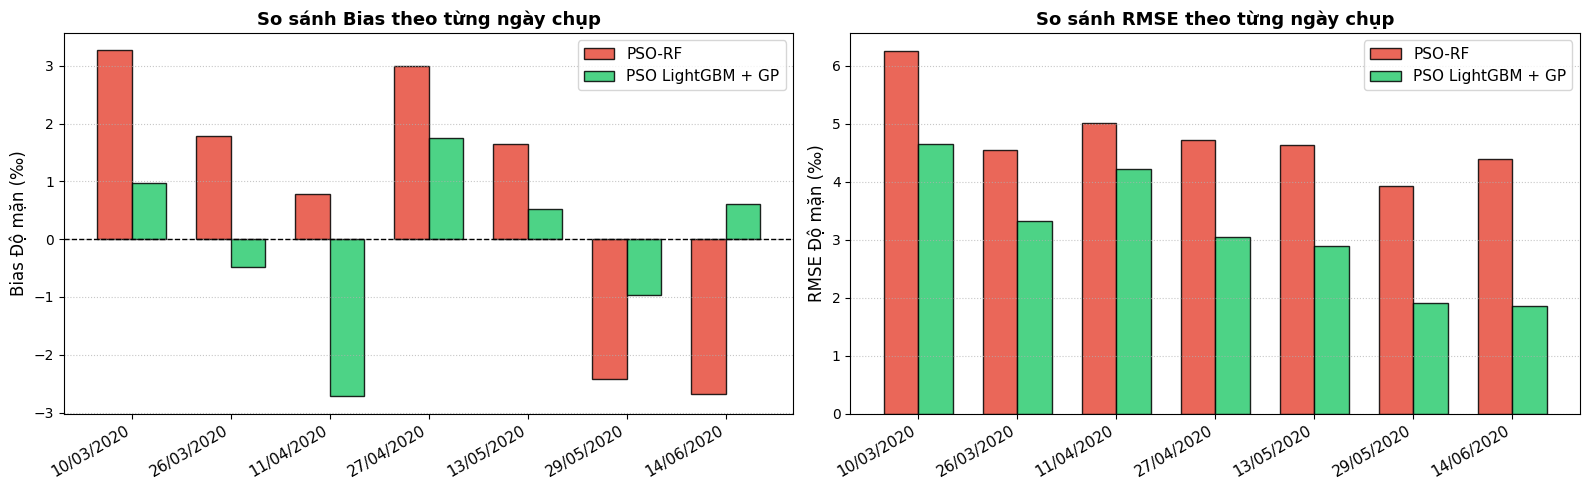

-> Đã lưu biểu đồ so sánh Daily Bias: daily_bias_pso_rf_vs_hybrid.png


In [79]:
# ==============================================================================
# BẢNG ĐỐI CHUẨN VÀ BIỂU ĐỒ DAILY BIAS: PSO-RF (GỐC) VS PHƯƠNG PHÁP MỚI (+ GP)
# ==============================================================================
import matplotlib.pyplot as plt

# Lấy dự báo của PSO-RF gốc và Mô hình đề xuất
pso_rf_pred = predictions['PSO RF']['tree_only']
hybrid_pred = predictions['PSO LightGBM']['hybrid']

df_daily = pd.DataFrame({
    'date': df_test['date'],
    'y_true': y_test,
    'pred_rf': pso_rf_pred,
    'pred_hybrid': hybrid_pred
})
df_daily['date_str'] = df_daily['date'].dt.strftime('%d/%m/%Y')
df_daily['bias_rf'] = df_daily['y_true'] - df_daily['pred_rf']
df_daily['bias_hybrid'] = df_daily['y_true'] - df_daily['pred_hybrid']
df_daily['sq_err_rf'] = (df_daily['y_true'] - df_daily['pred_rf']) ** 2
df_daily['sq_err_hybrid'] = (df_daily['y_true'] - df_daily['pred_hybrid']) ** 2

daily_summary = df_daily.groupby('date_str', sort=False).agg(
    n_samples=('y_true', 'count'),
    mean_obs=('y_true', 'mean'),
    bias_rf=('bias_rf', 'mean'),
    bias_hybrid=('bias_hybrid', 'mean'),
    rmse_rf=('sq_err_rf', lambda s: np.sqrt(np.mean(s))),
    rmse_hybrid=('sq_err_hybrid', lambda s: np.sqrt(np.mean(s)))
).reset_index()

daily_summary['abs_bias_impr'] = daily_summary['bias_rf'].abs() - daily_summary['bias_hybrid'].abs()
daily_summary['rmse_impr'] = daily_summary['rmse_rf'] - daily_summary['rmse_hybrid']

print('=' * 105)
print('BẢNG ĐỐI CHUẨN CHI TIẾT THEO TỪNG CẢNH NGÀY (DAILY BIAS & RMSE) TRÊN TẬP TEST 2020')
print('=' * 105)
display_df = daily_summary.rename(columns={
    'date_str': 'Ngày chụp',
    'n_samples': 'Số trạm',
    'mean_obs': 'Độ mặn TB (‰)',
    'bias_rf': 'Bias PSO-RF (‰)',
    'bias_hybrid': 'Bias Mới + GP (‰)',
    'rmse_rf': 'RMSE PSO-RF (‰)',
    'rmse_hybrid': 'RMSE Mới + GP (‰)',
    'abs_bias_impr': 'Cải thiện |Bias| (‰)',
    'rmse_impr': 'Cải thiện RMSE (‰)'
})
display(display_df.round(3))

# Vẽ biểu đồ cột đối chuẩn trực quan Daily Bias & Daily RMSE
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
x_indices = np.arange(len(daily_summary))
width = 0.35

# 1. Subplot Bias
axes[0].bar(x_indices - width/2, daily_summary['bias_rf'], width, label='PSO-RF', color='#e74c3c', alpha=0.85, edgecolor='black')
axes[0].bar(x_indices + width/2, daily_summary['bias_hybrid'], width, label='PSO LightGBM + GP', color='#2ecc71', alpha=0.85, edgecolor='black')
axes[0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0].set_xticks(x_indices)
axes[0].set_xticklabels(daily_summary['date_str'], rotation=30, ha='right', fontsize=11)
axes[0].set_ylabel('Bias Độ mặn (‰)', fontsize=12)
axes[0].set_title('So sánh Bias theo từng ngày chụp', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(axis='y', linestyle=':', alpha=0.7)

# 2. Subplot RMSE
axes[1].bar(x_indices - width/2, daily_summary['rmse_rf'], width, label='PSO-RF', color='#e74c3c', alpha=0.85, edgecolor='black')
axes[1].bar(x_indices + width/2, daily_summary['rmse_hybrid'], width, label='PSO LightGBM + GP', color="#2ecc71", alpha=0.85, edgecolor='black')
axes[1].set_xticks(x_indices)
axes[1].set_xticklabels(daily_summary['date_str'], rotation=30, ha='right', fontsize=11)
axes[1].set_ylabel('RMSE Độ mặn (‰)', fontsize=12)
axes[1].set_title('So sánh RMSE theo từng ngày chụp', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(axis='y', linestyle=':', alpha=0.7)

plt.tight_layout()
plt.savefig('daily_bias_pso_rf_vs_hybrid.png', dpi=300, bbox_inches='tight')
plt.show()
print('-> Đã lưu biểu đồ so sánh Daily Bias: daily_bias_pso_rf_vs_hybrid.png')
daily_summary.to_csv(f'result_daily_bias_{RUN_TAG}.csv', index=False)


**Cell 8: Trực quan hóa kết quả dự báo (Scatter Plot 1:1 & Phân tích sai số Residual)**
- Biểu đồ Scatter Plot phân tán (Observed vs Predicted) so sánh trực tiếp mô hình Đơn lẻ vs Mô hình Lai (+ GP).
- Đánh giá trực quan mức độ cải thiện và khả năng hội tụ dọc theo đường chéo 1:1.

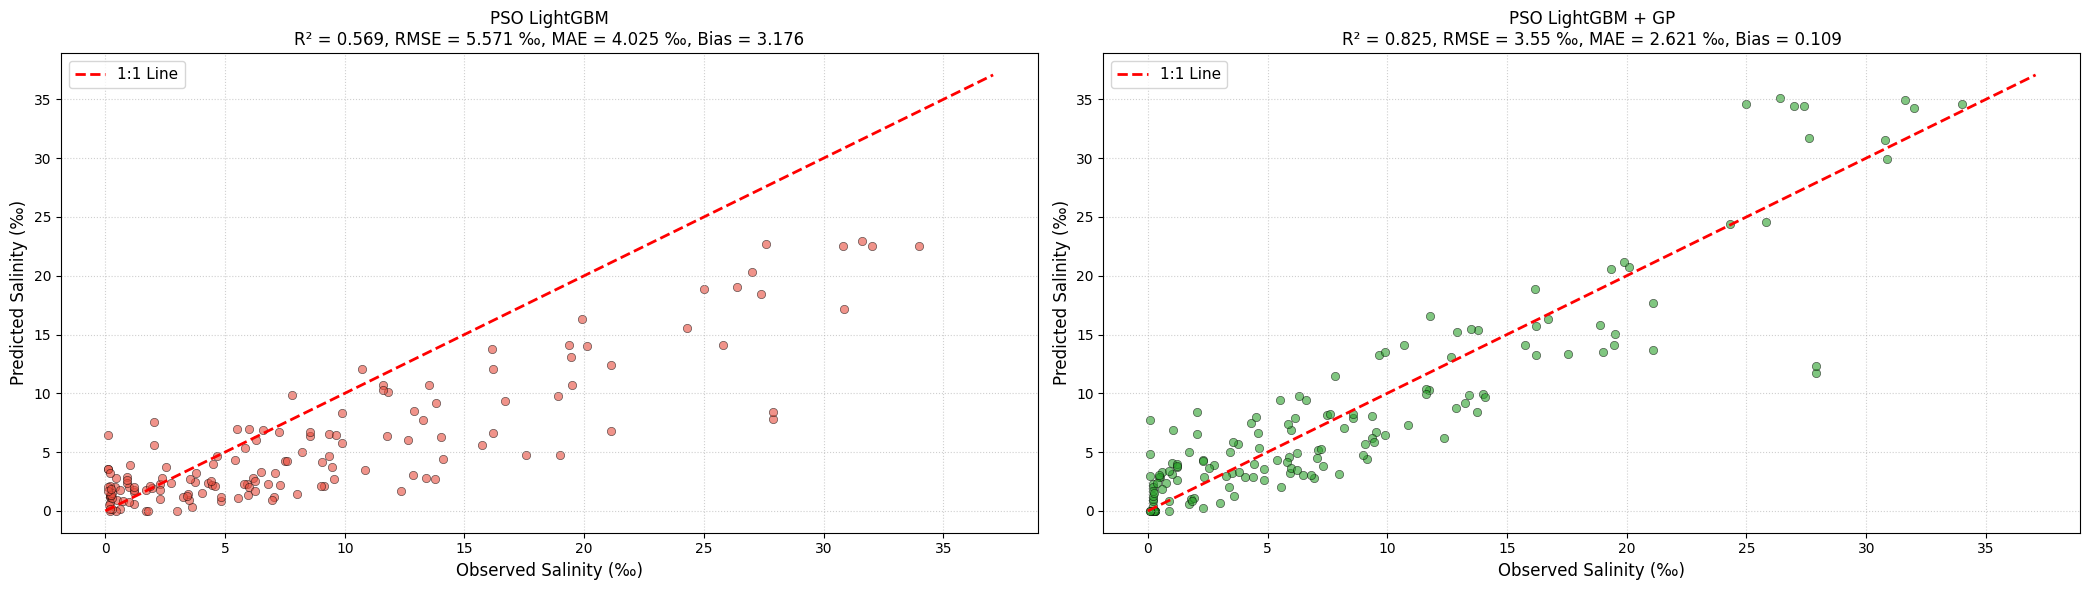

-> Đã lưu biểu đồ so sánh: scatter_plot_hybrid_gp_comparison.png


In [83]:
# Chọn mô hình để trực quan hóa
target_model = 'PSO LightGBM'
pred_te_pure   = predictions[target_model].get('tree_only', predictions[target_model]['base'])
pred_te_base   = predictions[target_model]['base']
pred_te_hybrid = predictions[target_model]['hybrid']
pred_te_roll   = predictions[target_model].get('rolling', pred_te_hybrid)

eval_pure = evaluate_model(y_test, pred_te_pure)
eval_base = evaluate_model(y_test, pred_te_base)
eval_hybr = evaluate_model(y_test, pred_te_hybrid)

panels = [
    (pred_te_pure,   f'{target_model}', eval_pure, '#e74c3c'),
    (pred_te_hybrid, f'{target_model} + GP', eval_hybr, '#2ca02c'),
]
fig, axes = plt.subplots(1, 2, figsize=(21, 6))
max_val = max(y_test.max(), *(p.max() for p, *_ in panels)) + 2
for ax, (p, title, ev, col) in zip(axes, panels):
    ax.scatter(y_test, p, alpha=0.6, edgecolors='k', linewidths=0.5, c=col)
    ax.plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='1:1 Line')
    ax.set_xlabel('Observed Salinity (‰)', fontsize=12)
    ax.set_ylabel('Predicted Salinity (‰)', fontsize=12)
    ax.set_title(f'{title}\nR² = {ev["R2"]}, RMSE = {ev["RMSE (‰)"]} ‰, MAE = {ev["MAE (‰)"]} ‰, Bias = {ev["Bias (‰)"]}', fontsize=12)
    ax.legend(fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('scatter_plot_hybrid_gp_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print('-> Đã lưu biểu đồ so sánh: scatter_plot_hybrid_gp_comparison.png')


**Cell 9: Ablation – mô hình đang dựa vào những nhóm biến nào?**
Bỏ lần lượt `sin_doy/cos_doy` và `Lat/Long` rồi chạy lại một mô hình (PSO LightGBM, không blend, không GP) để xem R² và bias thay đổi ra sao. Nếu bỏ `sin/cos_doy` mà bias giảm, mô hình đang bám vào mùa của năm 2019.

In [ ]:
print('Cờ USE_SEASONAL hiện tại =', USE_SEASONAL)

def eval_drop(drop, model=pso_lgbm_model):
    keep = [i for i, f in enumerate(base_cols) if f not in drop]
    m = clone(model).fit(X_train_base[:, keep], y_train)
    ev = evaluate_model(y_test, m.predict(X_test_base[:, keep]))
    return ev['R2'], ev['RMSE (‰)'], ev['Bias (‰)']

ablation_cases = {
    'Đầy đủ (38 biến)': [],
    'Bỏ sin/cos doy (mùa vụ)': ['sin_doy', 'cos_doy'],
    'Bỏ số ngày tuyệt đối t (dài hạn)': ['t'],
    'Bỏ cả t và sin/cos doy': ['t', 'sin_doy', 'cos_doy'],
    'Bỏ tọa độ Lat/Long': ['Lat', 'Long'],
    'Chỉ giữ 35 biến viễn thám': ['t', 'sin_doy', 'cos_doy', 'Lat', 'Long']
}
print(f'{"Cấu hình đặc trưng":38s} {"R2":>7s} {"RMSE (‰)":>10s} {"Bias (‰)":>10s}')
print('-' * 70)
for label, drop in ablation_cases.items():
    r2, rmse, bias = eval_drop(drop)
    print(f'{label:38s} {r2:7.3f} {rmse:10.3f} {bias:10.3f}')


**Quy trình chạy thí nghiệm gợi ý**
1. Chạy toàn bộ notebook một lần với cấu hình mặc định (có PSO). Ghi lại bảng tĩnh và bảng cuốn chiếu (đã có thêm Ex_VAR).
2. Cell 6.0 gợi ý `RECENCY_HALF_LIFE` bằng fold tiến. Đặt giá trị đó ở Cell 4 (hoặc chỉ chạy lại dòng `w_train = ...`) rồi chạy lại từ Cell 7.
3. Đặt `USE_SEASONAL = False`, chạy lại Cell 4, rồi chạy từ Cell 6.1 trở đi (không cần chạy lại PSO). Báo cáo cả hai cấu hình, vì fold trong train không đánh giá công bằng được sin/cos_doy.
4. Mỗi lần chạy lưu file `result_*_{RUN_TAG}.csv` riêng, nên các cấu hình không ghi đè lên nhau.
5. Khi báo cáo: nêu rõ bài toán (dự báo sau khi có ảnh của ngày đó, giai đoạn mới), đưa điểm tĩnh và điểm cuốn chiếu, và ghi giả định của cuốn chiếu (số đo của các cảnh trước đã có sẵn lúc dự báo).